# Podstawy AI – Logika rozmyta: decyzje i sterownik

Plan:
1. Wybór uczelni – czy operator „i” zmienia decyzję?
2. Sterownik pralki – od dwóch reguł do pełnego sterownika
3. Podsumowanie

**Jak pracujemy:**
- **TODO** w kodzie – tu piszesz kod lub zmieniasz liczby.
- **Testy** – komórka, którą uruchamiasz bez zmian. Wypisze `OK` albo `BŁĄD` z przypadkiem, który nie działa.
- **Pytanie** – odpowiadasz 2–3 zdaniami w komórce „Twoja odpowiedź”.

Kto zrobił wybór uczelni na poprzednich zajęciach, zaczyna od razu od części 2.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from functools import reduce

# ---- Gotowe funkcje z poprzednich zajęć ---------------------------------
def gamma(x, a, b):
    return np.clip((np.asarray(x, float) - a) / (b - a), 0, 1)

def L(x, a, b):
    return np.clip((b - np.asarray(x, float)) / (b - a), 0, 1)

def t(x, a, b, c):
    x = np.asarray(x, float)
    return np.clip(np.minimum((x - a) / (b - a), (c - x) / (c - b)), 0, 1)

def T_min(a, b):     return np.minimum(a, b)
def T_iloczyn(a, b): return np.asarray(a, float) * b
def T_luk(a, b):     return np.maximum(0, np.asarray(a, float) + b - 1)
def S_max(a, b):     return np.maximum(a, b)


def sprawdz(nazwa, f, przypadki):
    """Testuje funkcję f: przypadki = lista (argumenty, oczekiwany_wynik)."""
    bledy = 0
    for args, oczekiwane in przypadki:
        try:
            wynik = f(*args)
            ok = wynik is not None and np.allclose(np.asarray(wynik, float), oczekiwane, atol=1e-6, equal_nan=True)
        except Exception as e:
            wynik, ok = f"BŁĄD: {e}", False
        if not ok:
            bledy += 1
            arg = ", ".join(str(np.round(a, 3).tolist()) if isinstance(a, np.ndarray) else str(a) for a in args)
            print(f"BŁĄD  {nazwa}({arg}) = {wynik}, oczekiwano {oczekiwane}")
    print(f"OK    {nazwa}" if bledy == 0 else f"      {nazwa}: {bledy} błędnych przypadków")

---
## Część 1. Wybór uczelni – czy operator „i” zmienia decyzję?

Kandydat dostał się na 4 wydziały. Chce, żeby wydział był **wysoko w rankingu I blisko domu I miał dobrą wymianę I dawał dobre szanse na pracę**.

Dane są liczbami, a kryteria są rozmyte. Najpierw zamieniamy liczby na stopnie spełnienia kryteriów, a potem łączymy cztery kryteria operatorem „i” (t-normą).

### 1.1 Od danych do stopni

In [2]:
wydzialy = {
    #          miejsce w rankingu, odległość [km], uczelnie partnerskie, zatrudnienie [%]
    "w1": (19, 72, 20, 78),
    "w2": (4,  92, 35, 92),
    "w3": (35, 10, 12, 70),
    "w4": (12, 50,  7, 85),
}

def kryteria(ranking, odleglosc, wymiana, praca):
    return [
        L(ranking, 5, 40),        # 'wysoko w rankingu'
        L(odleglosc, 20, 150),    # 'blisko domu'
        gamma(wymiana, 5, 30),    # 'dobra wymiana'
        gamma(praca, 60, 90),     # 'dobre szanse na pracę'
    ]

def tabela_stopni(kryteria):
    stopnie = {w: kryteria(*d) for w, d in wydzialy.items()}
    print("      ranking  blisko  wymiana  praca")
    for w, s in stopnie.items():
        print(w, "  ", "   ".join(f"{float(x):5.2f}" for x in s))
    return stopnie

stopnie = tabela_stopni(kryteria)

      ranking  blisko  wymiana  praca
w1     0.60    0.60    0.60    0.60
w2     1.00    0.45    1.00    1.00
w3     0.14    1.00    0.28    0.33
w4     0.80    0.77    0.08    0.83


### 1.2 Cztery sposoby rozumienia „i”

`reduce(T, [k1, k2, k3, k4])` liczy „k1 i k2 i k3 i k4” wybraną t-normą. Dla porównania dodajemy średnią, która **nie** jest t-normą.

In [3]:
OPERATORY = {
    "minimum":            lambda s: float(reduce(T_min, s)),
    "iloczyn":            lambda s: float(reduce(T_iloczyn, s)),
    "Łukasiewicz":        lambda s: float(reduce(T_luk, s)),
    "średnia (to NIE i)": lambda s: float(np.mean(s)),
}

def ranking(stopnie):
    print(f"{'operator':<20}" + "".join(f"{w:>7}" for w in wydzialy) + "   kolejność")
    for nazwa, op in OPERATORY.items():
        oceny = {w: op(s) for w, s in stopnie.items()}
        kolejnosc = " > ".join(sorted(oceny, key=oceny.get, reverse=True))
        print(f"{nazwa:<20}" + "".join(f"{o:7.2f}" for o in oceny.values()) + "   " + kolejnosc)

ranking(stopnie)

operator                 w1     w2     w3     w4   kolejność
minimum                0.60   0.45   0.14   0.08   w1 > w2 > w3 > w4
iloczyn                0.13   0.45   0.01   0.04   w2 > w1 > w4 > w3
Łukasiewicz            0.00   0.45   0.00   0.00   w2 > w1 > w3 > w4
średnia (to NIE i)     0.60   0.86   0.44   0.62   w2 > w4 > w1 > w3


**Pytanie 1a.** Który wydział wygrywa przy minimum, a który przy iloczynie? Spójrz na tabelę stopni i wyjaśnij, **dlaczego** zwycięzca się zmienia.

**Pytanie 1b.** Średnia stawia w4 na drugim miejscu, choć wymiana ma tam stopień 0,08. Dlaczego średnia to nie jest „i”? Kiedy mimo to byłaby rozsądnym wyborem?

*Twoja odpowiedź:* 1a: Przy minimum wygrywa wydział w1 a przy iloczynie wygrywa wydział w2. Otrzymujemy tutaj różnych zwycięzców ponieważ korzystamy z różnych metod obliczania. W minimum wybieramy najmniejszą wartość spośród wszystkich a przy iloczynie mnożym wszystkie wartości.

1b. Średnia nie jest operatorem "i" ponieważ pozwala nam ona na zrekompensowanie niskich wartości, innymi wyższymi notami. Jest ona jednak dobrym wyborem w przypadku gdy uważamy, że jedno niskie kryterium nie przesądza całego wyniku.

### 1.3 Ty jesteś kandydatem

Kryteria w `kryteria()` wpisał ktoś inny. Teraz zdefiniuj je po swojemu.

1. Dla kandydata, dla którego odległość jest **bardzo** ważna, „blisko domu” znaczy co innego. Zmień to kryterium na `L(odleglosc, 10, 50)` i uruchom komórkę.
2. Potem zmień **jedno dowolne** kryterium tak, jak sam je rozumiesz.

In [14]:
def moje_kryteria(ranking, odleglosc, wymiana, praca):
    return [
        L(ranking, 5, 40),
        L(odleglosc, 10, 50),    # TODO: zmień na L(odleglosc, 10, 50)
        gamma(wymiana, 10, 60),
        gamma(praca, 60, 90),
    ]

moje_stopnie = tabela_stopni(moje_kryteria)
print()
ranking(moje_stopnie)

      ranking  blisko  wymiana  praca
w1     0.60    0.00    0.20    0.60
w2     1.00    0.00    0.50    1.00
w3     0.14    1.00    0.04    0.33
w4     0.80    0.00    0.00    0.83

operator                 w1     w2     w3     w4   kolejność
minimum                0.00   0.00   0.04   0.00   w3 > w1 > w2 > w4
iloczyn                0.00   0.00   0.00   0.00   w3 > w1 > w2 > w4
Łukasiewicz            0.00   0.00   0.00   0.00   w1 > w2 > w3 > w4
średnia (to NIE i)     0.35   0.62   0.38   0.41   w2 > w4 > w3 > w1


**Pytanie 1c.** Kto wygrywa po zmianie „blisko domu” na `L(odleglosc, 10, 50)`? Co bardziej zmienia decyzję: wybór operatora czy definicja kryterium?

**Pytanie 1d.** Który operator najlepiej oddaje to, jak **Ty** wybierałbyś uczelnię? Uzasadnij.

*Twoja odpowiedź:*
1c: Po zmianie wartości wygrywa oddział w3, ponieważ o wiele bardziej istotna staje się odległość od domu. Zmiana definicji kryterium znacznie bardziej zmienia finałową decyzję niż sam wybór operatora.

1d: Operatorem, który najlepiej oddaje to jaką uczelnie bym wybrał jest minimum, ponieważ osobiście nie chce kompromisów przy bardzo niskich wynikach.

---
## Część 2. Sterownik pralki

Budujemy **sterownik**: program, który z reguł JEŚLI–TO wylicza czas prania. Działa w pięciu krokach:

| krok | co się dzieje |
|---|---|
| 1. rozmycie | liczby (np. 55%, 4 kg) zamieniamy na stopnie: „brud duży w stopniu 0,38” |
| 2. siła reguł | ile prawdy jest w części JEŚLI każdej reguły (t-norma) |
| 3. implikacja | zbiór wyjściowy przycinamy (min) albo skalujemy (iloczyn) siłą reguły |
| 4. łączenie | wnioski wszystkich reguł łączymy w jeden kształt (maksimum) |
| 5. wyostrzanie | z kształtu robimy jedną liczbę minut |

Zaczniemy od pralki z dwiema regułami, znajdziemy jej wady na **mapie sterownika** i zbudujemy pełną wersję.

### 2.1 Zbiory rozmyte pralki

Każda zmienna ma swoje zbiory, zapisane jako słownik `{nazwa: funkcja}`. Na start pralka zna tylko kilka z nich.

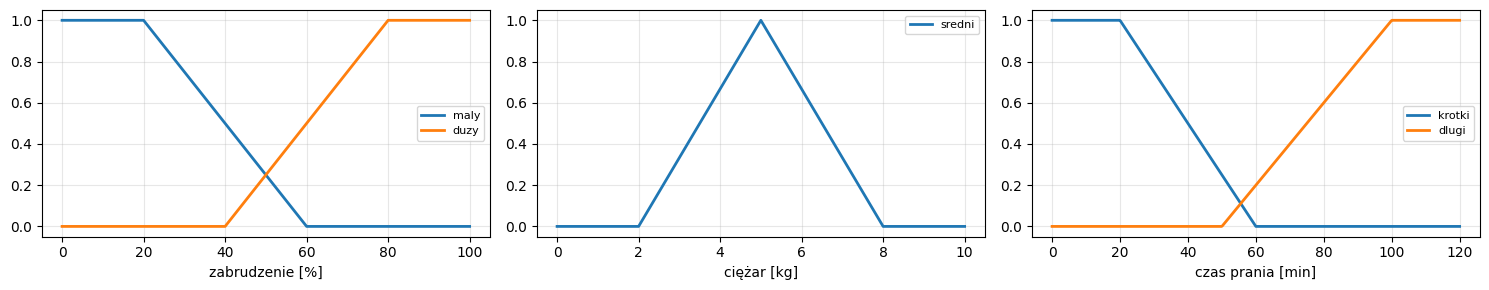

In [15]:
BRUD = {                                   # zabrudzenie [%], 0–100
    "maly": lambda x: L(x, 20, 60),
    "duzy": lambda x: gamma(x, 40, 80),
}
CIEZAR = {                                 # ciężar prania [kg], 0–10
    "sredni": lambda x: t(x, 2, 5, 8),
}
CZAS = {                                   # czas prania [min], 0–120
    "krotki": lambda x: L(x, 20, 60),
    "dlugi":  lambda x: gamma(x, 50, 100),
}

def rysuj_zbiory(BRUD, CIEZAR, CZAS):
    fig, osie = plt.subplots(1, 3, figsize=(15, 3))
    for os_, (nazwa, zbiory, zakres) in zip(osie, [("zabrudzenie [%]", BRUD, 100),
                                                   ("ciężar [kg]", CIEZAR, 10),
                                                   ("czas prania [min]", CZAS, 120)]):
        xs = np.linspace(0, zakres, 501)
        for n, f in zbiory.items():
            os_.plot(xs, f(xs), lw=2, label=n)
        os_.set_xlabel(nazwa); os_.legend(fontsize=8); os_.grid(alpha=.3)
    plt.tight_layout(); plt.show()

rysuj_zbiory(BRUD, CIEZAR, CZAS)

**Pytanie 2a.** Spójrz na wykres ciężaru. Jaki stopień ma „średni” ciężar dla 1 kg i dla 9 kg? Co to może oznaczać dla pralki?

*Twoja odpowiedź:* 2a: "Średni" ciężar dla 1kg i 9kg w obu przypadkach ma stopień równy 0. Dla pralki oznacza to że prania o takim ciężarze nie będą uznane za "średnie".

### 2.2 Środek ciężkości

Ostatni krok, **wyostrzanie**, zamienia kształt na jedną liczbę. Kształt to dwie tablice: `x` – możliwe czasy prania, `mu` – wysokość kształtu nad każdym czasem. Środek ciężkości to średnia ważona czasów, a wagą jest `mu`:

$$x^* = \frac{x_1 \mu_1 + x_2 \mu_2 + \dots}{\mu_1 + \mu_2 + \dots}$$

Przykład: x = 0, 10, 20, 30 i mu = 0; 1; 0; 0,5 daje (10 · 1 + 30 · 0,5) / (1 + 0,5) = 25 / 1,5 ≈ 16,67.

Zaimplementuj tę funkcję. Jeśli wszystkie `mu` są zerami (żadna reguła nie zadziałała), zwróć `np.nan`.

In [18]:
def srodek_ciezkosci(x, mu):
    x, mu = np.asarray(x, float), np.asarray(mu, float)
    # TODO
    if np.sum(mu) == 0:
        return np.nan
    return np.sum(x * mu) / np.sum(mu)

In [19]:
# Testy
xs = np.array([0.0, 10.0, 20.0, 30.0])
sprawdz("srodek_ciezkosci", srodek_ciezkosci, [((xs, np.array([0, 1, 1, 0])), 15),
                                             ((xs, np.array([0, 0, 0, 1])), 30),
                                             ((xs, np.array([1, 0, 0, 1])), 15),
                                             ((xs, np.array([0, 1, 0, 0.5])), 50 / 3),
                                             ((xs, np.array([0, 0, 0, 0])), np.nan)])

OK    srodek_ciezkosci


### 2.3 Sterownik z dwiema regułami i mapa sterownika

Reguły zapisujemy jako słownik `{(brud, ciężar): czas}`. `None` znaczy „dowolny ciężar”:

- **R1:** JEŚLI brud **duży** I ciężar **średni**, TO czas **długi**
- **R2:** JEŚLI brud **mały**, TO czas **krótki**

Funkcja `sterownik` wykonuje pięć kroków dla dowolnego zestawu reguł. Nie musisz jej zmieniać – przeczytaj komentarze.

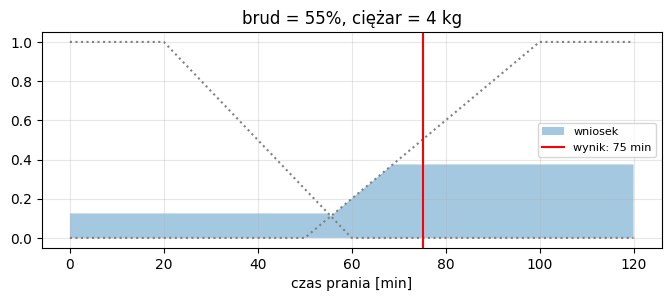

55%, 4 kg -> 75 min


In [20]:
czas = np.linspace(0, 120, 1201)

def srodek_maksimum(x, mu):
    """Inna metoda wyostrzania: środek przedziału, w którym kształt jest najwyższy."""
    if np.max(mu) == 0:
        return np.nan
    return x[np.isclose(mu, np.max(mu))].mean()

def sterownik(brud, ciezar, reguly, T=T_min, implikacja="min", wyostrzanie=None, pokaz=False):
    wyostrzanie = wyostrzanie or srodek_ciezkosci
    # 1. rozmycie wejść
    st_brud = {n: float(f(brud)) for n, f in BRUD.items()}
    st_ciezar = {n: float(f(ciezar)) for n, f in CIEZAR.items()}
    wynik = np.zeros_like(czas)
    for (b, c), wyjscie in reguly.items():
        # 2. siła reguły (None = dowolny ciężar)
        sila = st_brud[b] if c is None else float(T(st_brud[b], st_ciezar[c]))
        # 3. implikacja: "min" przycina zbiór wyjściowy, "iloczyn" go skaluje
        zbior = CZAS[wyjscie](czas)
        wniosek = np.minimum(sila, zbior) if implikacja == "min" else sila * zbior
        # 4. łączenie wniosków
        wynik = S_max(wynik, wniosek)
    # 5. wyostrzanie
    x_star = wyostrzanie(czas, wynik)
    if pokaz:
        plt.figure(figsize=(8, 2.8))
        for n, f in CZAS.items():
            plt.plot(czas, f(czas), ":", c="gray")
        plt.fill_between(czas, wynik, alpha=.4, label="wniosek")
        if not np.isnan(x_star):
            plt.axvline(x_star, c="r", label=f"wynik: {x_star:.0f} min")
        plt.title(f"brud = {brud}%, ciężar = {ciezar} kg"); plt.xlabel("czas prania [min]")
        plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()
    return x_star


REGULY_2 = {
    ("duzy", "sredni"): "dlugi",    # R1
    ("maly", None):     "krotki",   # R2
}

print(f"55%, 4 kg -> {sterownik(55, 4, REGULY_2, pokaz=True):.0f} min")

Sprawdzanie sterownika punkt po punkcie jest żmudne. **Mapa sterownika** liczy wynik dla wszystkich kombinacji zabrudzenia i ciężaru naraz. Białe pola to miejsca, gdzie **żadna reguła nie działa**.

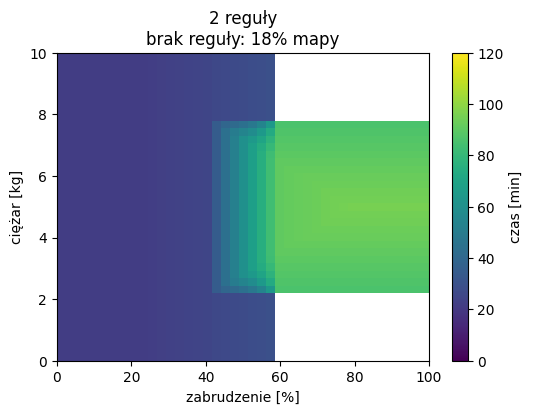

In [21]:
def mapa(reguly, ax=None, tytul="", **ustawienia):
    brudy = np.linspace(0, 100, 41)
    ciezary = np.linspace(0, 10, 41)
    Z = np.array([[sterownik(b, c, reguly, **ustawienia) for b in brudy] for c in ciezary])
    ax = ax or plt.subplots(figsize=(6, 4))[1]
    im = ax.imshow(Z, origin="lower", aspect="auto", extent=[0, 100, 0, 10], cmap="viridis", vmin=0, vmax=120)
    ax.set_xlabel("zabrudzenie [%]"); ax.set_ylabel("ciężar [kg]")
    ax.set_title(f"{tytul}\nbrak reguły: {np.isnan(Z).mean() * 100:.0f}% mapy")
    plt.colorbar(im, ax=ax, label="czas [min]")
    return Z

Z_2 = mapa(REGULY_2, tytul="2 reguły")
plt.show()

**Pytanie 2b.** Gdzie na mapie są białe pola? Opisz słowami, jakie to prania. Co zrobi prawdziwa pralka, gdy sterownik nie zwróci żadnej liczby?

**Pytanie 2c.** Na mapie widać prostokąt, w którym kolor zmienia się gwałtownie. Gdzie leży i skąd się bierze?

*Twoja odpowiedź:*
2b. Białe pola na mapie występują w miejscach gdzie żadne z reguł nie obowiązują. Jest to pranie o dużym % zabrudzeniu i jednocześnie małym lub dużym ciężarze. PRawdziwa pralka w sytuacji gdy sterownik nie zwróci żadnej liczby albo zawiesi się albo rozpocznie pranie z domyślną wartością.

2c. Gwałtowna zmiana koloru występuje w miejscu gdzie przestaje dziłać reguła R2 a zaczyna przeważać reguła R1 co powoduje zmianę koloru.

### 2.4 Pełna baza reguł

Zbuduj pralkę, która ma regułę na **każdą** sytuację: 3 stany zabrudzenia × 3 stany ciężaru = 9 reguł.

1. **Uzupełnij zbiory:** dodaj `"sredni"` do `BRUD`, `"lekki"` i `"ciezki"` do `CIEZAR` oraz `"sredni"` i `"bardzo_dlugi"` do `CZAS`. Możesz zmienić istniejące zbiory. Sąsiednie zbiory muszą się **nakładać**.
2. **Uzupełnij tabelę reguł:** w każdą komórkę słownika `REGULY_9` wpisz `"krotki"`, `"sredni"`, `"dlugi"` albo `"bardzo_dlugi"`.
3. Uruchom mapę i poprawiaj, aż białe pola znikną, a mapa będzie miała sens (więcej brudu i większy ciężar → dłużej).

In [22]:
# TODO 1: uzupełnij zbiory (możesz też zmienić istniejące)
BRUD = {
    "maly":   lambda x: L(x, 20, 60),
    "sredni": lambda x: t(x, 30, 50, 70),
    "duzy":   lambda x: gamma(x, 40, 80),
}
CIEZAR = {
    "lekki":  lambda x: L(x, 0, 3),
    "sredni": lambda x: t(x, 2, 5, 8),
    "ciezki": lambda x: gamma(x, 7, 10),
}
CZAS = {
    "krotki": lambda x: L(x, 20, 60),
    "sredni": lambda x: t(x, 40, 55, 70),
    "dlugi":  lambda x: gamma(x, 50, 100),
    "bardzo_dlugi": lambda x: gamma(x, 80, 120),
}

# TODO 2: uzupełnij tabelę reguł (zamień None na nazwę zbioru czasu)
REGULY_9 = {
    ("maly",   "lekki"):  "krotki",
    ("maly",   "sredni"): "krotki",
    ("maly",   "ciezki"): "sredni",
    ("sredni", "lekki"):  "sredni",
    ("sredni", "sredni"): "dlugi",
    ("sredni", "ciezki"): "bardzo_dlugi",
    ("duzy",   "lekki"):  "sredni",
    ("duzy",   "sredni"): "dlugi",
    ("duzy",   "ciezki"): "bardzo_dlugi",
}

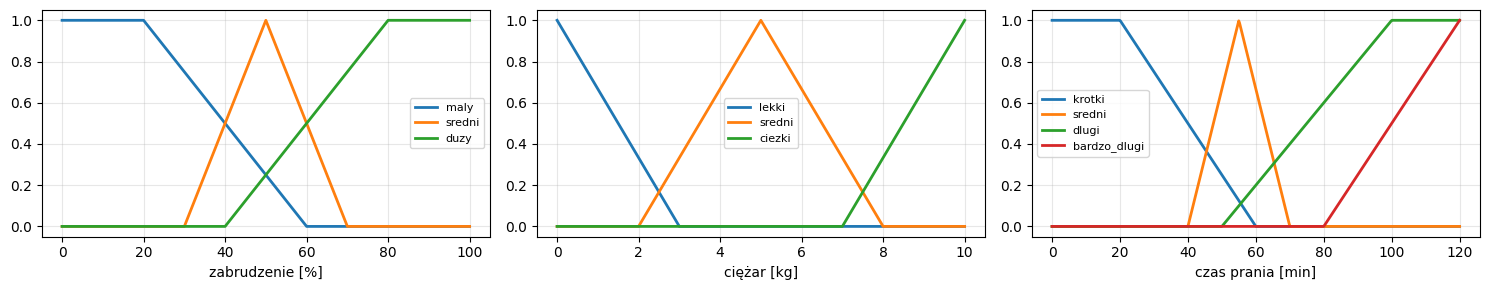

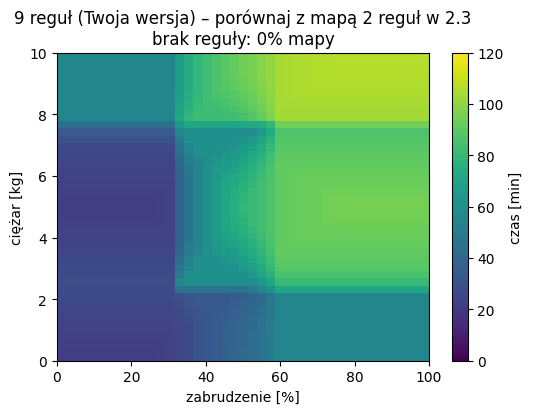

brud 10%, ciężar 1 kg -> 24 min
brud 55%, ciężar 4 kg -> 82 min
brud 70%, ciężar 3 kg -> 89 min
brud 90%, ciężar 9 kg -> 106 min


In [24]:
# Uruchamiaj po każdej zmianie
brakuje = [k for k, v in REGULY_9.items() if v is None or k[0] not in BRUD or k[1] not in CIEZAR or v not in CZAS]
if brakuje:
    print("Nie wszystko gotowe – sprawdź te reguły:", brakuje)
else:
    rysuj_zbiory(BRUD, CIEZAR, CZAS)
    Z_9 = mapa(REGULY_9, tytul="9 reguł (Twoja wersja) – porównaj z mapą 2 reguł w 2.3")
    plt.show()
    for b, c in [(10, 1), (55, 4),(70, 3), (90, 9)]:
        print(f"brud {b}%, ciężar {c} kg -> {sterownik(b, c, REGULY_9):.0f} min")

**Pytanie 2d.** Porównaj swoją mapę z mapą osoby obok. Wybierz jeden punkt (np. 70%, 3 kg), dla którego Wasze pralki dają najbardziej różne czasy. Kto ma rację – i jak można by to rozstrzygnąć?

**Pytanie 2e.** 2 wejścia po 3 stany to 9 reguł. Ile reguł trzeba by napisać dla 5 wejść po 3 stany? Co to mówi o ręcznym pisaniu reguł?

*Twoja odpowiedź:* 2d. Otrzymane wyniki nie różniły się znacznie poza wartościami przy większym zabrudzeniu powyżej 90% i również wysokim ciężarze powyżej 9kg, gdzie czas prania osoby obok był lekko mniejszy. Jedynym sposobem na rozstrzygnięcie takie sporu byłoby faktyczne przetestowanie sterowników i ocenienie efektów prania w obu przypadkach.

2e. Dla 5 wejść i 3 stanów mamy ilość reguł równą 3^5 czyli 243. Pokazuje to, że ręczne pisanie reguł nie jest efektywnym sposobem przy rosnącej ilości zmiennych.

### 2.5 Która decyzja projektowa ma największe znaczenie?

Ten sam sterownik ma trzy „pokrętła”: t-normę w części JEŚLI, implikację i metodę wyostrzania. Porównajmy, jak bardzo każde z nich zmienia całą mapę.

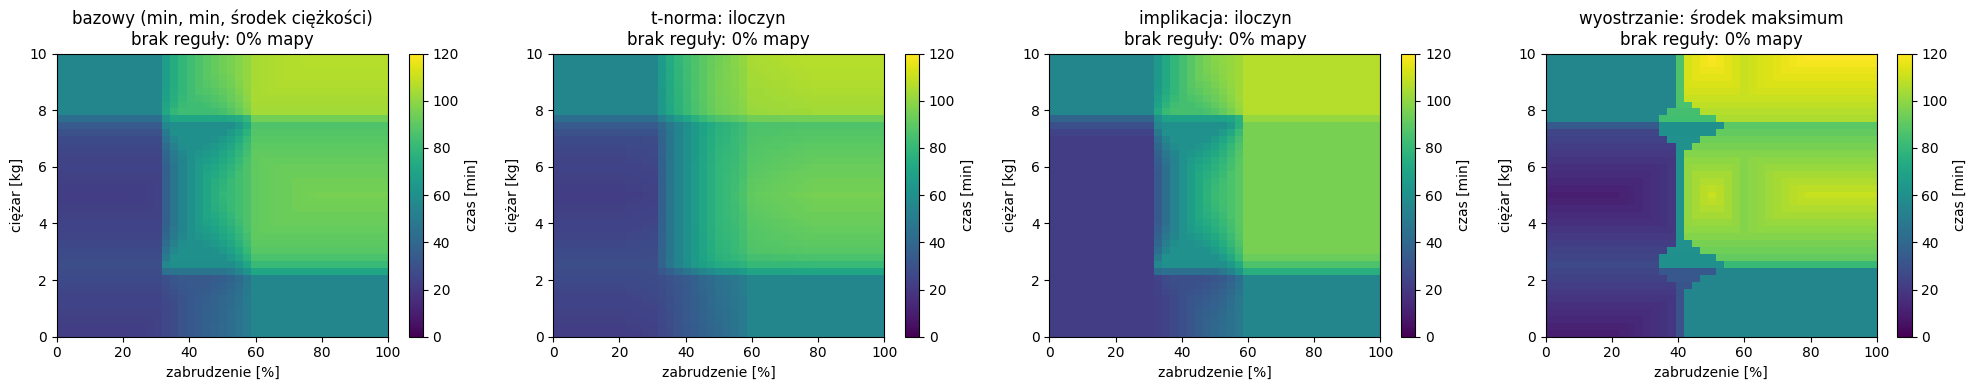

t-norma: iloczyn                 średnia różnica:  1.1 min, największa: 18.2 min
implikacja: iloczyn              średnia różnica:  2.4 min, największa:  8.1 min
wyostrzanie: środek maksimum     średnia różnica:  8.8 min, największa: 37.0 min


In [25]:
warianty = {
    "bazowy (min, min, środek ciężkości)": {},
    "t-norma: iloczyn":                    {"T": T_iloczyn},
    "implikacja: iloczyn":                 {"implikacja": "iloczyn"},
    "wyostrzanie: środek maksimum":        {"wyostrzanie": srodek_maksimum},
}
if brakuje:
    print("Najpierw dokończ 2.4 – ta część używa Twojej pełnej bazy reguł.")
else:
    fig, osie = plt.subplots(1, 4, figsize=(20, 4))
    mapy = {n: mapa(REGULY_9, os_, n, **u) for os_, (n, u) in zip(osie, warianty.items())}
    plt.tight_layout(); plt.show()

    Z0 = mapy["bazowy (min, min, środek ciężkości)"]
    for n, Z in list(mapy.items())[1:]:
        d = np.abs(Z - Z0)
        print(f"{n:<32} średnia różnica: {np.nanmean(d):4.1f} min, największa: {np.nanmax(d):4.1f} min")

**Pytanie 2f.** Które pokrętło najbardziej zmienia sterownik? Która mapa ma wyraźne „schodki” (skoki koloru)?



*Twoja odpowiedź:* 2f. Na sterownik najbardziej wpływa metoda wyostrzania. Wyraźne schodki możemy również zaobserwować przy wykorzystaniu tej metody na mapie 4 z wykorzystaniem wyostrzania: środek maksimum.

### 2.6 Dla chętnych: trzecie wejście

Dodaj wejście **rodzaj tkaniny** z dwoma stanami: `"delikatna"` i `"zwykla"` (np. skala 0–10). Delikatna tkanina powinna skracać pranie.

1. Ile reguł potrzebuje pełna baza dla 3 wejść (3 × 3 × 2)?
2. Funkcja `sterownik` obsługuje tylko dwa wejścia. Co trzeba w niej zmienić, żeby obsłużyła trzecie?
3. Zaproponuj, jak uniknąć pisania wszystkich reguł (np. jedna reguła „JEŚLI tkanina delikatna, TO czas krótki” zamiast dziewięciu).